# Introduction

## What is a jupyter notebook

We are running the codes in a Jupyter Notebook environment.  

Jupyter Notebook is an interactive computing environment that allows you to write and execute code, visualize data, and document your workflow in a single document. It is widely used in data science, machine learning, and scientific computing due to its flexibility and ease of use.  

A Jupyter Notebook consists of two main types of cells:  

- **Code Cells:** These contain executable code. When you run a code cell, the output (such as numerical results, plots, or tables) is displayed directly below it.  
- **Markdown Cells:** These contain formatted text, explanations, equations, and images. Markdown cells are useful for adding descriptions, instructions, and documentation to make the notebook more readable and informative.  

By combining code and markdown cells, Jupyter Notebook provides an efficient way to write, execute, and document code in one place.

In [1]:
# this is a code cell
x = 1
print(x)

1


This is a markdown cell

To run a cell in a Jupyter Notebook, simply click on it and press **Shift + Enter** or click the **Run** button in the toolbar. You can execute cells in any order, meaning you don’t have to run them sequentially from top to bottom. However, keep in mind that the execution order affects the notebook's state, so if a later cell depends on variables or functions defined in an earlier cell, make sure those have been run first. You can check the execution order by looking at the number next to each code cell.

In [2]:
## TRY HERE

In [3]:
## TRY HERE

## What you will do

### Dataset

This tutorial features an image dataset from a 2012 survey in Haig Fras, UK.  

The dataset consists of raw seafloor visual images captured during a survey within the Greater Haig Fras Marine Conservation Zone (MCZ) in the central Celtic Sea. This was the first in a series of surveys conducted at this location. A camera system mounted on the autonomous underwater vehicle (AUV) Autosub6000 was deployed during the RRS Discovery cruise 377/8 (D377/8), capturing images along four 4.7 km transect lines.

<img src="https://github.com/paidiver/paidiver-workshop/blob/main/docs/assets/benthic_cc1.png?raw=true" alt="Map of Greater Haig Fras in the Celtic Sea" style="width:500px;"/>

The images were already georeferenced and tiled. This is an example of an input image:

<img src="https://github.com/paidiver/paidiver-workshop/blob/main/docs/assets/benthic_cc2.png?raw=true" alt="Greater Haig Fras seafloor imagery" style="width:100px;"/>

This is just a part of the dataset. The full dataset with the metadata file are available here: https://www.bodc.ac.uk/data/published_data_library/catalogue/10.5285/090239b1-b7dd-1030-e063-6c86abc-0e183

### Metadata

This dataset has a IFDO standard metadata file: https://ifdo-schema.org/. More details about metadata can be seen in the metadata folder.

### Processing

Start with the dataset and the provided metadata. Run the cells from top to bottom with **Shift+Enter**. In a YAML file, spaces group settings and each item under `steps` is applied in order.

1. **Open a small subset.** The opening step reads the JPEG images and their iFDO metadata. Fixed sampling keeps five images so the first run is quick enough to repeat.
2. **Convert to grayscale.** Work with brightness alone so it is easier to see the next filter's effect on texture. Compare the result with the original before deciding whether colour is useful for your question.
3. **Apply gentle Gaussian blur.** Average nearby intensities to soften fine noise. Look at a small edge before and after the blur. The same operation can also hide fine biological features.

Inspect the image gallery before exporting. Each column shows another stage for the same input. Restart the kernel and run from the top if an earlier variable is missing.

## Paidiverpy pipeline

### Minimal Pipeline Execution: Runs in just **3 lines of code**

```python
from paidiverpy.pipeline import Pipeline # import the package
pipeline = Pipeline(config_file_path="config/dsp/config_introduction.yml") # instantiate the class
pipeline.run() # run the pipeline
```

If you want to export the outputs, you need to run an extra line:

```python
pipeline.save_images() # export the images to the output path
```

### Read the configuration

Both platform configurations use the published Haig Fras sample. Paidiverpy resolves the image folder and iFDO metadata from `sample_data` and stores them locally for the next run.

```yaml
general:
  input_path: paidiver/tutorials/images/benthic_ifdo
  output_path: output/1_introduction
  metadata_path: paidiver/tutorials/metadata/benthic_ifdo.json
  metadata_type: ifdo
  n_jobs: 1
  sampling:
    - mode: fixed
      params:
        value: 5
steps:
  - colour:
      name: grayscale
      mode: grayscale
  - colour:
      name: gentle_blur
      mode: gaussian_blur
      params:
        sigma: 1.0
```

You can use the same configuration on a laptop or a workshop server.

## Running the code

First, you need to set your correct configuration file path. Considering that you followed the instruction in the setup to download the data, your configuration file path should be as follow below:

In [6]:
from os import chdir
from pathlib import Path

tutorial_dir = Path.home() / "paidiver" / "tutorials"
chdir(tutorial_dir)

**!IMPORTANT: YOU MAY NEED TO UPDATE THE OUTPUT PATH ON THE CONFIGURATION FILE**

### Import the libraries


In [7]:
import paidiverpy
from paidiverpy.pipeline import Pipeline

### Check version

Check if the version of paidiverpy is correct (expect 0.4.2)

In [9]:
print(f"Paidiverpy version: {paidiverpy.__version__}")

Paidiverpy version: 0.4.2


### Instantiate the paipiline class

In [12]:
pipeline = Pipeline(config_file_path="config/config_introduction.yml")

☁ paidiverpy ☁  |    WARNING | 2026-11-27 16:08:32 | Failed to validate the IFDO metadata.
You can continue, but some functions may not work properly.
Please set verbose to 3 (DEBUG) to see the validation errors.
☁ paidiverpy ☁  |    WARNING | 2026-11-27 16:08:32 | Metadata does not have a camera-position type column. It should have one of the following columns: ['camera-position', 'camera_position', 'altitude_m', 'altitude_metre', 'altitude_meters', 'altitude_meter', 'image-altitude-meters']. 

☁ paidiverpy ☁  |    WARNING | 2026-11-27 16:08:32 | Metadata does not have a depth type column. It should have one of the following columns: ['depth', 'depth_m', 'depth_metres', 'depth_metre', 'depth_meters', 'depth_meter', 'image-depth']. 

☁ paidiverpy ☁  |    WARNING | 2026-11-27 16:08:32 | Metadata does not have a pitch type column. It should have one of the following columns: ['pitch', 'Pitch', 'Pitch_deg', 'pitch_deg', 'image-camera-pitch-degrees']. 

☁ paidiverpy ☁  |    WARNING | 2026-

**You may see some warnings above. If you're not using any functions that require depth data, you can safely ignore them.**  

When you create a `Pipeline` instance, the code reads the configuration file and metadata, then validates them. If any issues are found, you'll receive an error message explaining the problem.

### Show the pipeline

To check the pipeline steps, you just need to run `pipeline`. You can also click in a step to see more information about it

In [13]:
pipeline

### Run the pipeline and inspect the images

Run the cell and expand the gallery to compare the grayscale and blurred results. Once you have checked them, run `pipeline.save_images(image_format="png")` in a new code cell to write the final images under `output/introduction`.

In [15]:
pipeline.run()

☁ paidiverpy ☁  |       INFO | 2026-11-27 16:09:13 | Processing images using 1 cores
☁ paidiverpy ☁  |       INFO | 2026-11-27 16:09:13 | Running step 0: raw - OpenLayer
☁ paidiverpy ☁  |       INFO | 2026-11-27 16:09:14 | Step 0 completed
☁ paidiverpy ☁  |       INFO | 2026-11-27 16:09:15 | Running step 1: grayscale - ColourLayer
☁ paidiverpy ☁  |       INFO | 2026-11-27 16:09:15 | Step 1 completed
☁ paidiverpy ☁  |       INFO | 2026-11-27 16:09:15 | Running step 2: gentle_blur - ColourLayer
☁ paidiverpy ☁  |       INFO | 2026-11-27 16:09:15 | Step 2 completed



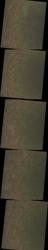
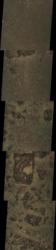
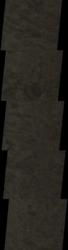
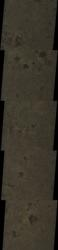
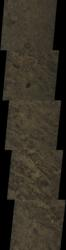
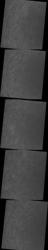
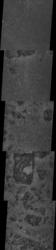
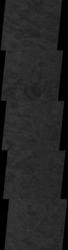
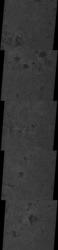
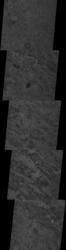
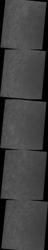
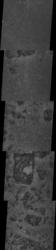
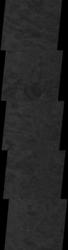
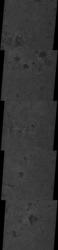
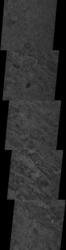

In [16]:
pipeline.images

### Export images in png format

In [17]:
pipeline.save_images(image_format="png")

☁ paidiverpy ☁  |       INFO | 2026-11-27 16:09:53 | Saving images from step: last
☁ paidiverpy ☁  |       INFO | 2026-11-27 16:09:54 | Images are saved to the path: output/introduction


## Running the same code on the command line

**In real-life applications, Jupyter Notebook is primarily used for exploration and investigation. Once you are satisfied with your pipeline, running the code from the command line is often more efficient, providing better performance and faster execution.**

```bash
cd ~/paidiver-workshop/tutorials

# if you are using DSP
paidiverpy -c "config/dsp/config_introduction.yml"

# if you are using JASMIN
paidiverpy -c "config/jasmin/config_introduction.yml"
```

## Running the same code in the UI

**In Paidiverpy you can also use our UI for exploration and investigation, in the same way as the jupyter notebook**

```bash
cd ~/paidiver-workshop/tutorials

paidiverpy --gui
```

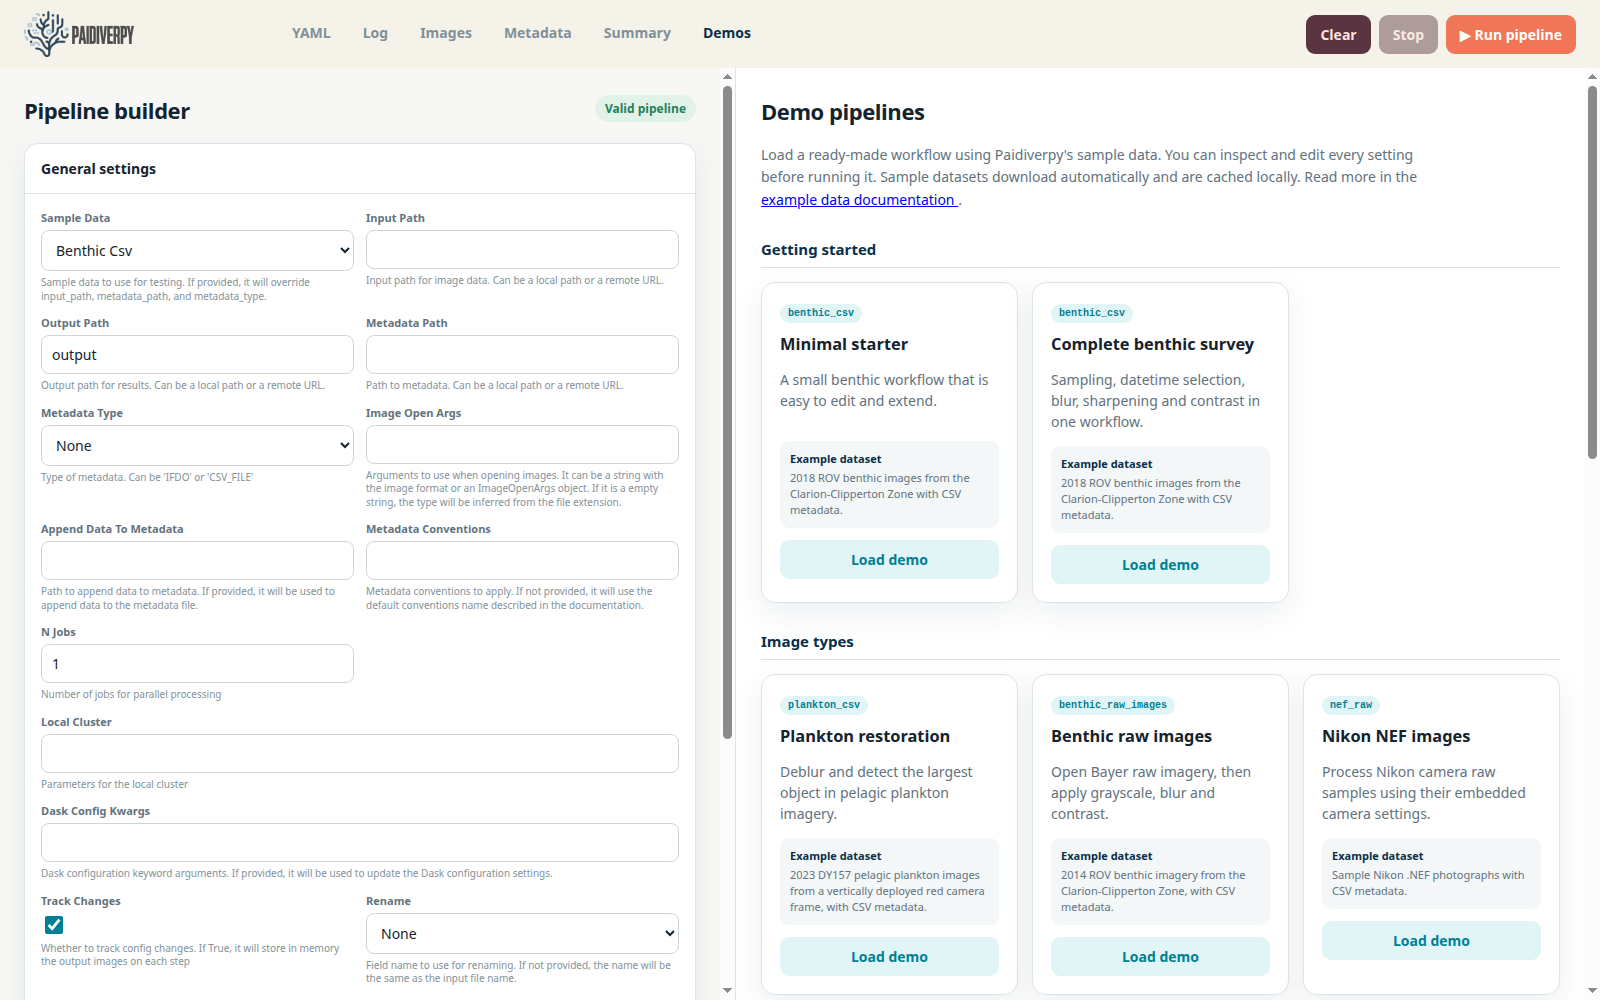

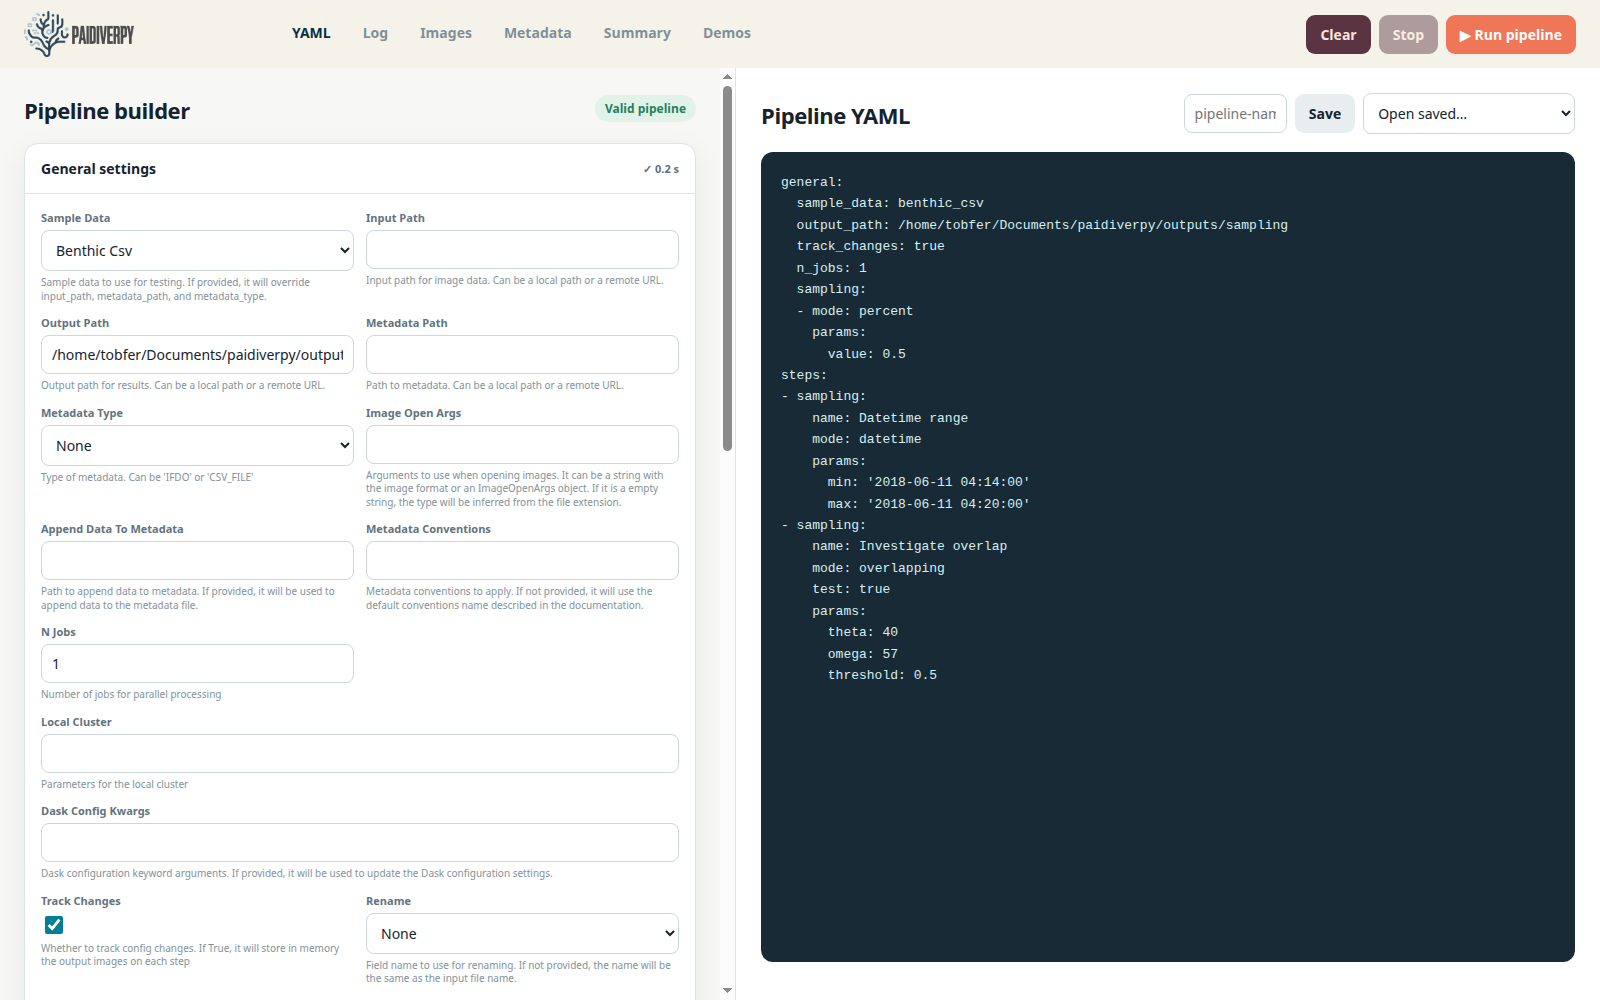

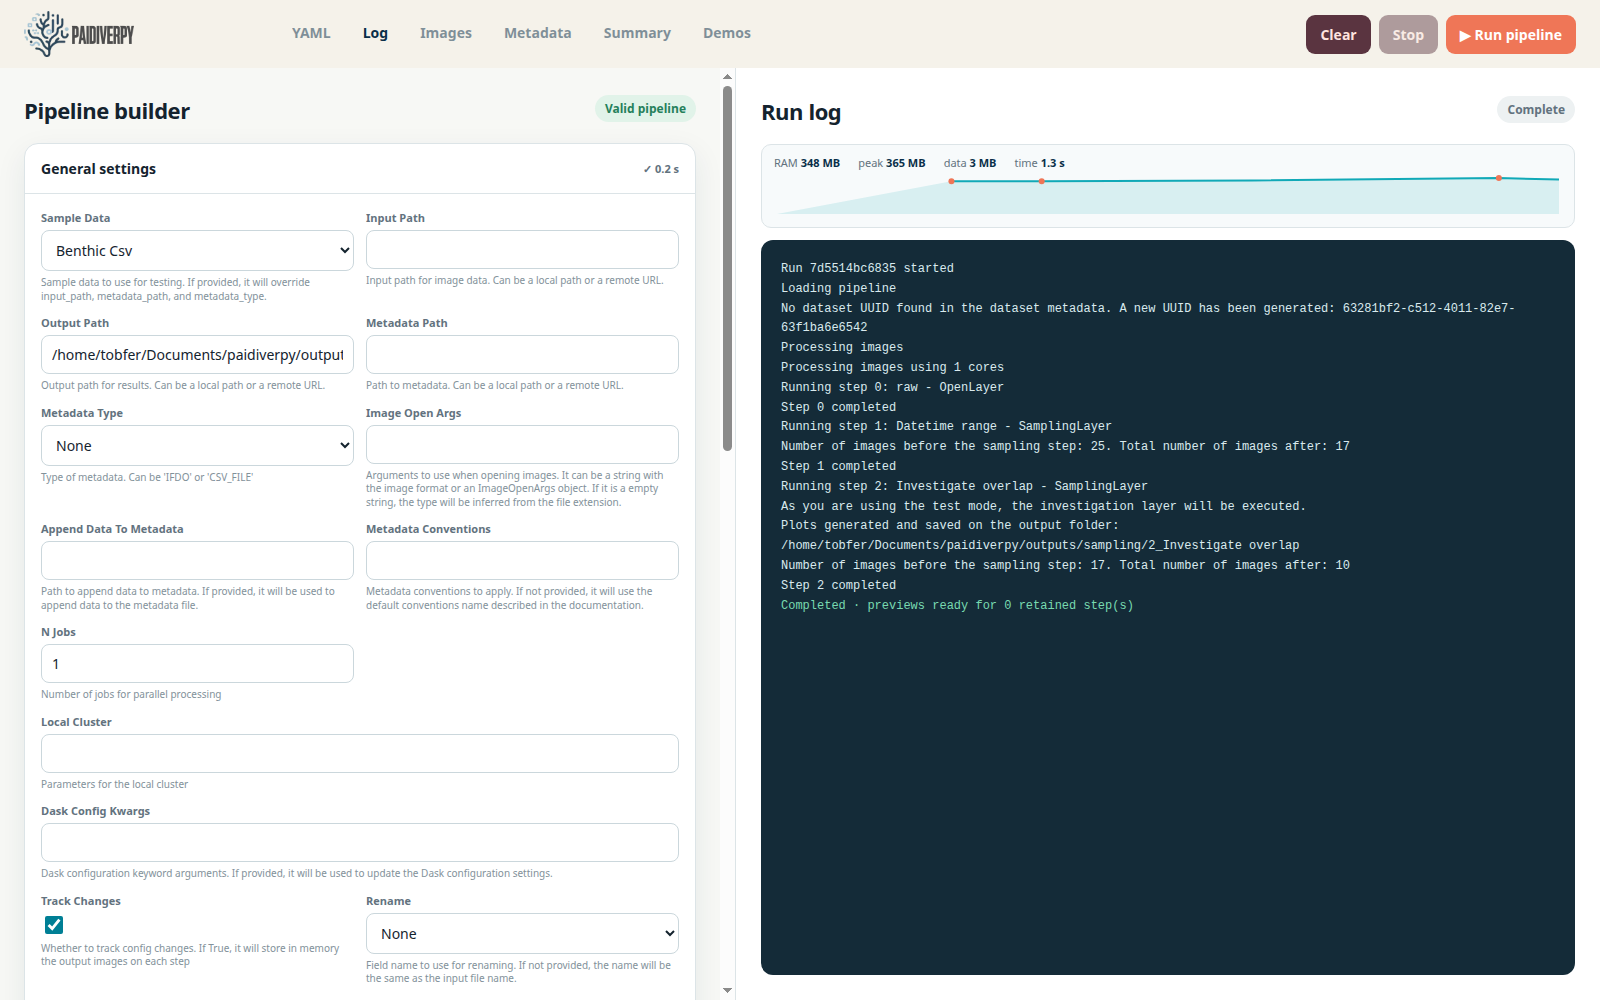

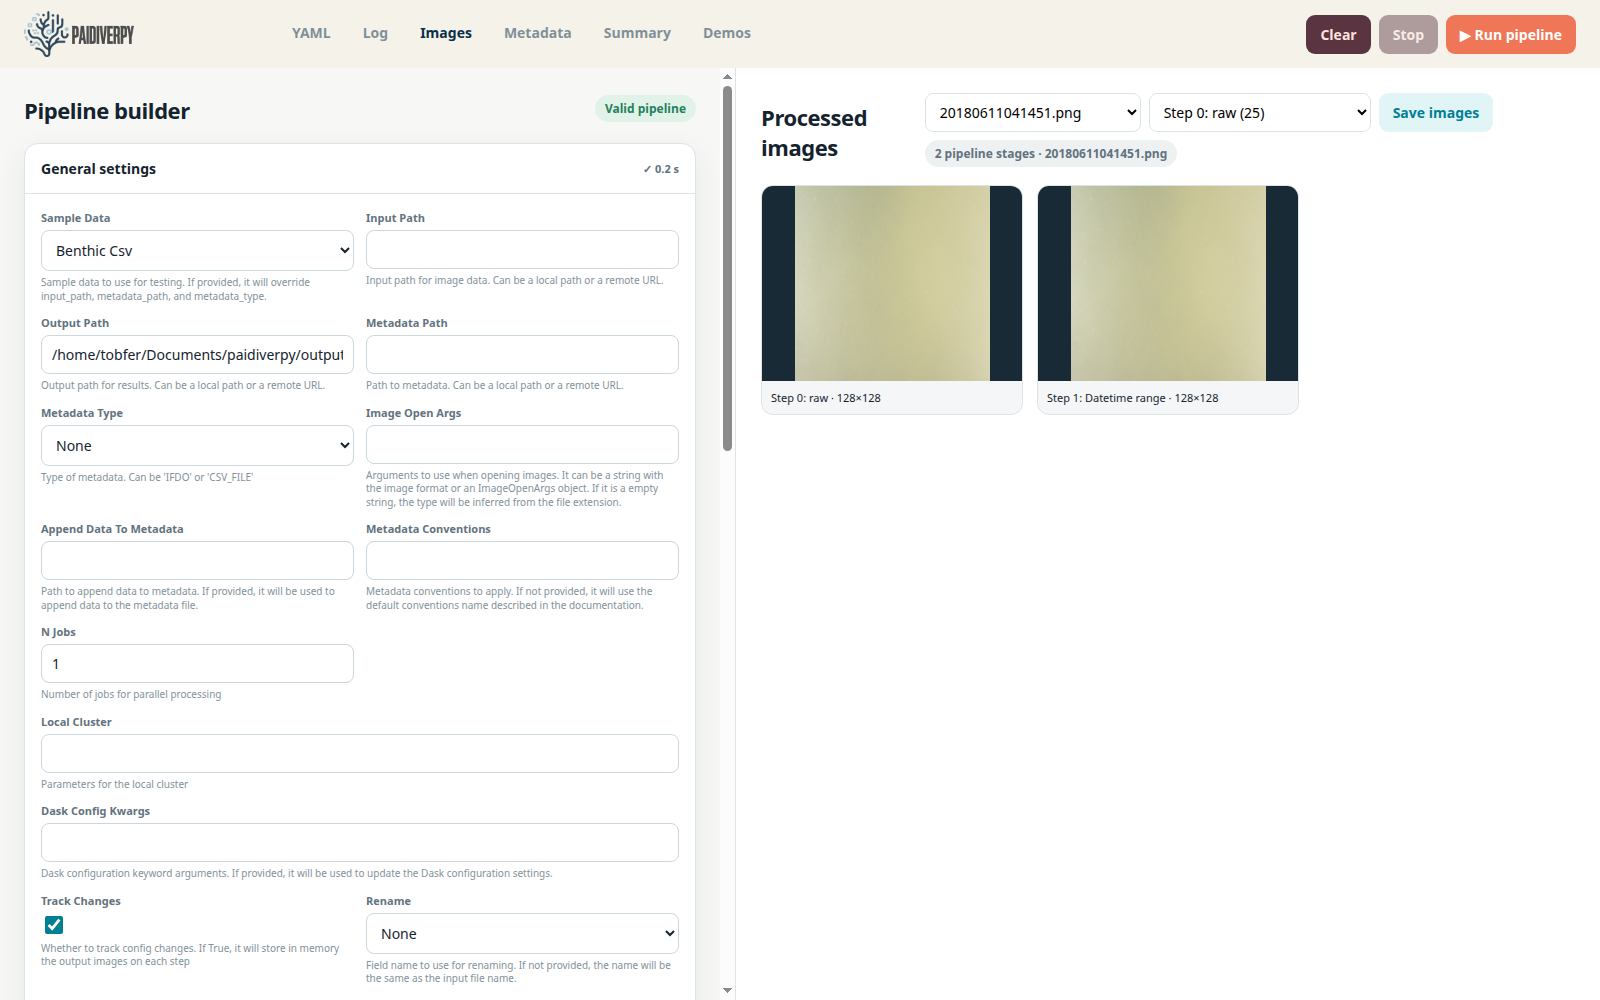